# 07 · Experimentos v5 — Exploración ampliada

## Estructura

| Exp | Cambio | Tiempo est. | Hipótesis |
|---|---|---|---|
| A | `is_unbalance=True` | ~3 min | Hiperparámetro más impactante según literatura para desbalance extremo |
| B | `boosting_type='dart'` | ~5 min | Dropout en árboles reduce overfitting en datasets ruidosos |
| C | Ventana deslizante (solo 2 meses recientes) | ~3 min | Reduce efecto del drift detectado en EDA |
| D | Kitchen sink — Optuna con TODO | ~40 min | Optuna encuentra interacciones que los experimentos individuales no ven |

A, B, C usan los params de v4 como base — solo cambian un factor.  
D explora el espacio completo incluyendo `boosting_type`, `is_unbalance`, `min_child_samples` hasta 2000, `min_split_gain` y ventana de entrenamiento como hiperparámetro.

El ganador entre {A, B, C, D} va al walk-forward completo y al semillerio.

---
**Proyecto:** Predicción de Churn Bancario · Data Mining en EyF  
**Etapa:** 7 — Experimentos v5  
**Última actualización:** 2026-10

## 0 · Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install optuna lightgbm --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 15.2 MB/s eta 0:00:00


In [3]:
import gc
import json
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import lightgbm as lgb
import optuna
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)
plt.rcParams['figure.dpi'] = 110

# ─── Rutas ────────────────────────────────────────────────────────────────────
RUTA_BASE  = Path('/content/drive/MyDrive/Maestría Data Mining/DM en EyF')
RUTA_COMP  = RUTA_BASE / 'Competencia 1'
RUTA_SUBS  = RUTA_COMP / 'submissions2'
RUTA_SUBS.mkdir(parents=True, exist_ok=True)

CKPT_B    = RUTA_COMP / 'dataset_fe_v3.parquet'
CKPT_V4   = RUTA_COMP / 'mejores_params_optuna_v4.json'
CKPT_V5   = RUTA_COMP / 'mejores_params_optuna_v5.json'
ARCHIVO_METRICAS = RUTA_COMP / 'metricas_experimentos.csv'

# ─── Constantes ───────────────────────────────────────────────────────────────
COL_ID      = 'numero_de_cliente'
COL_PERIODO = 'foto_mes'
TARGET_RAW  = 'clase_ternaria'
TARGET      = 'es_baja2'

MESES_CON_TARGET = [202103, 202104, 202105, 202106]
MES_PREDECIR     = 202108
GANANCIA_TP      =  1_072_500
COSTO_FP         =    -27_500
SEED             = 42

# Referencia v4 (último resultado conocido)
G_V4 = {'fold_2': None, 'fold_3': None, 'fold_4': None}  # se llena desde el json

def mem_mb(df): return df.memory_usage(deep=True).sum() / 1024**2

print('Checkpoints:')
for ck in [CKPT_B, CKPT_V4, CKPT_V5]:
    print(f'  {ck.name}: {"✓" if ck.exists() else "✗"}')

Checkpoints:
  dataset_fe_v3.parquet: ✓
  mejores_params_optuna_v4.json: ✓
  mejores_params_optuna_v5.json: ✗


## 1 · Funciones base

In [4]:
def ganancia_por_threshold(y_true, y_prob, n=500):
    thresholds = np.linspace(0.001, 0.999, n)
    rows = []
    for t in thresholds:
        pred = (y_prob >= t).astype(int)
        tp = ((y_true == 1) & (pred == 1)).sum()
        fp = ((y_true == 0) & (pred == 1)).sum()
        rows.append({'threshold': t,
                     'ganancia': tp * GANANCIA_TP + fp * COSTO_FP,
                     'tp': int(tp), 'fp': int(fp),
                     'n_intervenidos': int(tp + fp)})
    return pd.DataFrame(rows)

def threshold_optimo(y_true, y_prob):
    df_t = ganancia_por_threshold(y_true, y_prob)
    return df_t.loc[df_t['ganancia'].idxmax()].to_dict()

def evaluar_fold(y_true, y_prob, label=''):
    """Evalúa un fold y retorna dict con todas las métricas."""
    auc = roc_auc_score(y_true, y_prob)
    opt = threshold_optimo(y_true, y_prob)
    print(f'  [{label}] AUC={auc:.4f} | Ganancia=${opt["ganancia"]:,.0f} | '
          f'N={opt["n_intervenidos"]:,} | TP={opt["tp"]} | FP={opt["fp"]} | '
          f'thresh={opt["threshold"]:.4f}')
    return {'auc': round(auc, 4), **opt}

def plot_comparativa(resultados: dict, titulo='Comparativa de experimentos'):
    """
    resultados: {nombre_exp: {'fold_2': {...}, 'fold_3': {...}, 'fold_4': {...}}}
    """
    folds = ['fold_2', 'fold_3', 'fold_4']
    exps  = list(resultados.keys())
    x     = np.arange(len(folds))
    w     = 0.8 / len(exps)
    colores = ['#B0BEC5', '#4C72B0', '#DD8452', '#55A868', '#C44E52']

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Ganancia
    ax = axes[0]
    for i, (exp, datos) in enumerate(resultados.items()):
        ganancias = [datos.get(f, {}).get('ganancia', 0) / 1e9 for f in folds]
        offset = (i - len(exps)/2 + 0.5) * w
        ax.bar(x + offset, ganancias, w * 0.9,
               label=exp, color=colores[i % len(colores)], edgecolor='white')
    ax.set_title(titulo + '\nGanancia por fold', fontweight='bold')
    ax.set_ylabel('Ganancia ($B)')
    ax.set_xticks(x)
    ax.set_xticklabels(folds)
    ax.axhline(0, color='gray', ls='--', lw=1)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.2f}B'))
    ax.legend(fontsize=9)

    # AUC
    ax = axes[1]
    for i, (exp, datos) in enumerate(resultados.items()):
        aucs = [datos.get(f, {}).get('auc', 0) for f in folds]
        offset = (i - len(exps)/2 + 0.5) * w
        ax.bar(x + offset, aucs, w * 0.9,
               label=exp, color=colores[i % len(colores)], edgecolor='white')
    ax.set_title(titulo + '\nAUC por fold', fontweight='bold')
    ax.set_ylabel('AUC')
    ax.set_xticks(x)
    ax.set_xticklabels(folds)
    ax.set_ylim(0.5, 1.0)
    ax.legend(fontsize=9)

    plt.tight_layout()
    plt.show()

print('✓ Funciones listas.')

✓ Funciones listas.


## 2 · Carga de datos y params base

In [5]:
df = pd.read_parquet(CKPT_B)
df = df.sort_values([COL_ID, COL_PERIODO]).reset_index(drop=True)
print(f'Dataset: {df.shape[0]:,} × {df.shape[1]} — {mem_mb(df):.1f} MB')

EXCLUIR = {COL_ID, COL_PERIODO, TARGET_RAW, TARGET}
FEATURE_COLS = [c for c in df.columns if c not in EXCLUIR]

# Ratio de desbalance
mask_e = df[COL_PERIODO].isin(MESES_CON_TARGET) & df[TARGET].notna()
y_ref  = df.loc[mask_e, TARGET]
SCALE_NATURAL = float((y_ref == 0).sum() / (y_ref == 1).sum())
del y_ref; gc.collect()
print(f'scale_pos_weight natural: {SCALE_NATURAL:.1f}')

# Params v4 como base para A, B, C
with open(CKPT_V4) as f:
    p_v4 = json.load(f)
PARAMS_BASE = {k: v for k, v in p_v4.items()
               if k not in {'ganancia_optuna_fold4','auc_fold4','n_trials','fecha','experimento'}}
PARAMS_BASE.update({'objective':'binary','metric':'binary_logloss',
                    'boosting_type':'gbdt','verbosity':-1,'n_jobs':-1,'random_state':SEED})
G_V4['fold_4'] = p_v4.get('ganancia_optuna_fold4', None)
print(f'\nParams v4 base cargados. Ganancia v4 fold_4: ${G_V4["fold_4"]:,.0f}')

FOLDS = [
    {'nombre': 'fold_2', 'train': [202103],                 'test': 202104},
    {'nombre': 'fold_3', 'train': [202103, 202104],         'test': 202105},
    {'nombre': 'fold_4', 'train': [202103, 202104, 202105], 'test': 202106},
]

def get_split(meses_train, mes_test, target_col=TARGET):
    mt = df[COL_PERIODO].isin(meses_train) & df[target_col].notna()
    me = (df[COL_PERIODO] == mes_test)      & df[target_col].notna()
    return (df.loc[mt, FEATURE_COLS], df.loc[mt, target_col].astype(int),
            df.loc[me, FEATURE_COLS], df.loc[me, target_col].astype(int))

Dataset: 983,061 × 327 — 1041.6 MB
scale_pos_weight natural: 158.8

Params v4 base cargados. Ganancia v4 fold_4: $380,050,000


---
## 3 · Experimento A — `is_unbalance=True`

**Hipótesis:** `is_unbalance` ajusta los pesos de clase inversamente proporcional a sus frecuencias de forma automática. La literatura lo identifica como el hiperparámetro de mayor impacto individual en datasets desbalanceados (Caballero 2024, KTH). En nuestro dataset con 158:1, puede detectar más churners que `scale_pos_weight` fijo.

**Nota técnica:** `is_unbalance=True` y `scale_pos_weight` son mutuamente excluyentes — no se pueden usar juntos.

In [6]:
params_A = {k: v for k, v in PARAMS_BASE.items()}
params_A.pop('scale_pos_weight', None)   # eliminamos scale_pos_weight
params_A['is_unbalance'] = True

resultados_A = {}
print('=== EXPERIMENTO A — is_unbalance=True ===')

for fold in FOLDS:
    Xtr, ytr, Xte, yte = get_split(fold['train'], fold['test'])
    modelo = lgb.LGBMClassifier(**params_A)
    modelo.fit(Xtr, ytr,
               eval_set=[(Xte, yte)],
               callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(-1)])
    prob = modelo.predict_proba(Xte)[:, 1]
    resultados_A[fold['nombre']] = evaluar_fold(yte.values, prob, f"A {fold['nombre']}")
    del Xtr, ytr, Xte, yte, modelo, prob; gc.collect()

print(f"\nResumen A — fold_4: ${resultados_A['fold_4']['ganancia']:,.0f}")

=== EXPERIMENTO A — is_unbalance=True ===
  [A fold_2] AUC=0.8387 | Ganancia=$451,935,000 | N=8,846.0 | TP=632.0 | FP=8214.0 | thresh=0.0310
  [A fold_3] AUC=0.8556 | Ganancia=$194,315,000 | N=7,694.0 | TP=369.0 | FP=7325.0 | thresh=0.0350
  [A fold_4] AUC=0.8665 | Ganancia=$354,420,000 | N=11,632.0 | TP=613.0 | FP=11019.0 | thresh=0.0290

Resumen A — fold_4: $354,420,000


---
## 4 · Experimento B — DART boosting

**Hipótesis:** `boosting_type='dart'` aplica dropout a los árboles durante el boosting — en cada ronda descarta aleatoriamente un subconjunto de árboles antes de ajustar el nuevo. Esto reduce el overfitting en datasets con muchas features ruidosas (tenemos ~280 features con importancia=0). Puede mejorar la generalización entre folds.

**Parámetros adicionales de DART:**
- `drop_rate`: fracción de árboles a dropear por ronda (default 0.1)
- `skip_drop`: probabilidad de saltear el dropout en una ronda (default 0.5)
- `uniform_drop`: si True, todos los árboles tienen igual probabilidad de ser dropeados

**Nota:** DART no es compatible con early_stopping de la misma forma que GBDT — desactivamos early stopping y fijamos n_estimators.

In [7]:
params_B = {k: v for k, v in PARAMS_BASE.items()}
params_B['boosting_type'] = 'dart'
params_B['drop_rate']     = 0.1
params_B['skip_drop']     = 0.5
# DART no se puede usar con early stopping — fijamos n_estimators
params_B['n_estimators']  = params_B.get('n_estimators', 300)

resultados_B = {}
print('=== EXPERIMENTO B — DART boosting ===')

for fold in FOLDS:
    Xtr, ytr, Xte, yte = get_split(fold['train'], fold['test'])
    modelo = lgb.LGBMClassifier(**params_B)
    # DART: sin early stopping callback
    modelo.fit(Xtr, ytr, callbacks=[lgb.log_evaluation(-1)])
    prob = modelo.predict_proba(Xte)[:, 1]
    resultados_B[fold['nombre']] = evaluar_fold(yte.values, prob, f"B {fold['nombre']}")
    del Xtr, ytr, Xte, yte, modelo, prob; gc.collect()

print(f"\nResumen B — fold_4: ${resultados_B['fold_4']['ganancia']:,.0f}")

=== EXPERIMENTO B — DART boosting ===
  [B fold_2] AUC=0.9091 | Ganancia=$514,552,500 | N=10,809.0 | TP=738.0 | FP=10071.0 | thresh=0.8250
  [B fold_3] AUC=0.8908 | Ganancia=$284,295,000 | N=8,022.0 | TP=459.0 | FP=7563.0 | thresh=0.8610
  [B fold_4] AUC=0.8969 | Ganancia=$390,610,000 | N=11,996.0 | TP=655.0 | FP=11341.0 | thresh=0.8010

Resumen B — fold_4: $390,610,000


---
## 5 · Experimento C — Ventana deslizante

**Hipótesis:** El EDA detectó drift en varias variables entre 202103 y 202108. Entrenar con datos más antiguos puede confundir al modelo con patrones que ya no aplican. Con ventana de 2 meses, cada fold entrena solo con los 2 meses inmediatamente anteriores al test.

**Configuración:**
- fold_4: entrena solo con [202104, 202105], predice 202106
- fold_3: entrena solo con [202103, 202104], predice 202105  
- fold_2: solo tiene [202103] → ventana de 1 mes (igual que antes)

**Nota:** fold_2 no cambia porque solo hay 1 mes disponible de todas formas.

In [8]:
params_C = {k: v for k, v in PARAMS_BASE.items()}

# Folds con ventana deslizante de 2 meses
FOLDS_VENTANA = [
    {'nombre': 'fold_2', 'train': [202103],          'test': 202104},  # sin cambio
    {'nombre': 'fold_3', 'train': [202103, 202104],  'test': 202105},  # sin cambio (ya eran 2)
    {'nombre': 'fold_4', 'train': [202104, 202105],  'test': 202106},  # CAMBIO: excluye 202103
]

resultados_C = {}
print('=== EXPERIMENTO C — Ventana deslizante (2 meses) ===')
print('fold_4: entrena con [202104, 202105] en vez de [202103, 202104, 202105]')

for fold in FOLDS_VENTANA:
    Xtr, ytr, Xte, yte = get_split(fold['train'], fold['test'])
    print(f"  {fold['nombre']}: train={len(ytr):,} (baja2={ytr.sum()}) | test={len(yte):,}")
    modelo = lgb.LGBMClassifier(**params_C)
    modelo.fit(Xtr, ytr,
               eval_set=[(Xte, yte)],
               callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(-1)])
    prob = modelo.predict_proba(Xte)[:, 1]
    resultados_C[fold['nombre']] = evaluar_fold(yte.values, prob, f"C {fold['nombre']}")
    del Xtr, ytr, Xte, yte, modelo, prob; gc.collect()

print(f"\nResumen C — fold_4: ${resultados_C['fold_4']['ganancia']:,.0f}")

=== EXPERIMENTO C — Ventana deslizante (2 meses) ===
fold_4: entrena con [202104, 202105] en vez de [202103, 202104, 202105]
  fold_2: train=161,881 (baja2=960) | test=162,320
  [C fold_2] AUC=0.8540 | Ganancia=$452,925,000 | N=8,490.0 | TP=624.0 | FP=7866.0 | thresh=0.0430
  fold_3: train=324,201 (baja2=2099) | test=162,625
  [C fold_3] AUC=0.8451 | Ganancia=$177,292,500 | N=5,313.0 | TP=294.0 | FP=5019.0 | thresh=0.0410
  fold_4: train=324,945 (baja2=2009) | test=163,240
  [C fold_4] AUC=0.8395 | Ganancia=$319,715,000 | N=17,174.0 | TP=720.0 | FP=16454.0 | thresh=0.0370

Resumen C — fold_4: $319,715,000


---
## 6 · Comparativa A vs B vs C vs v4

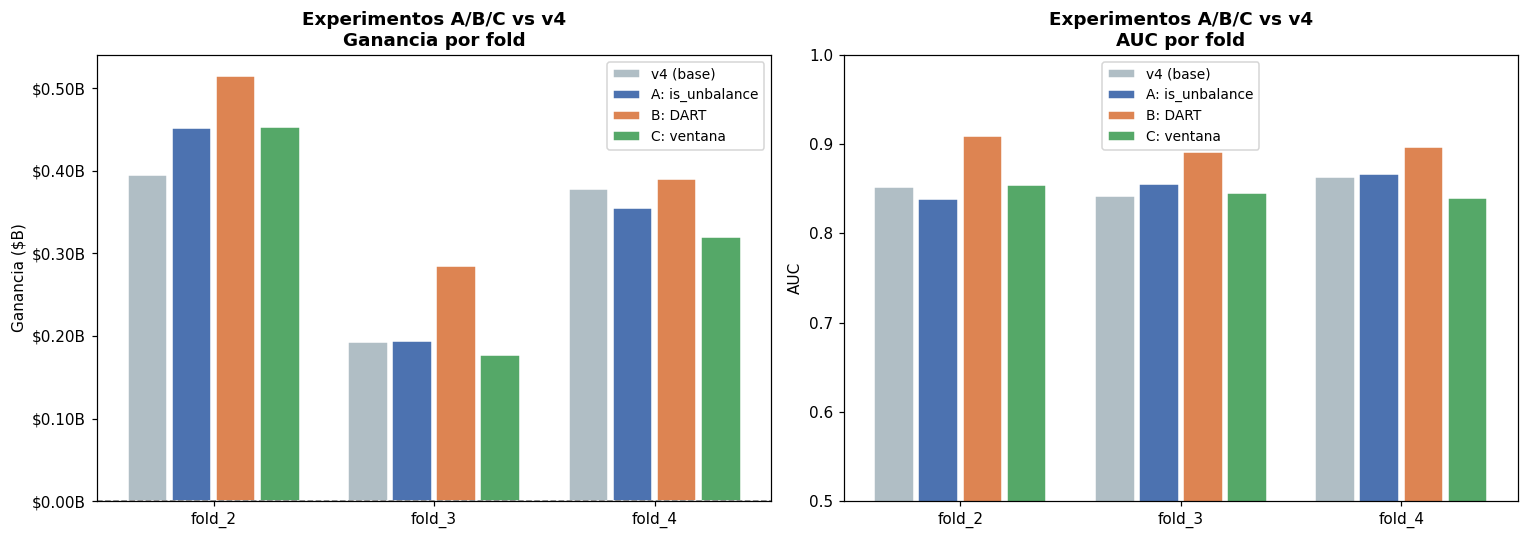


Resumen fold_4 (el más relevante):
         Experimento |           Ganancia |        vs v4 |      AUC |  N intervenidos
────────────────────────────────────────────────────────────────────────────────
           v4 (base) | $    377,685,000 | +$     0.0M |   0.8631 |               0
     A: is_unbalance | $    354,420,000 | $   -23.3M |   0.8665 |        11,632.0
             B: DART | $    390,610,000 | +$    12.9M |   0.8969 |        11,996.0
          C: ventana | $    319,715,000 | $   -58.0M |   0.8395 |        17,174.0

→ Ganador de A/B/C: Experimento B ($390,610,000)
→ Ahora corremos el Kitchen Sink (D) para ver si supera a todos


In [9]:
# Cargamos resultados de v4 desde el archivo de métricas para comparar
metricas_hist = pd.read_csv(ARCHIVO_METRICAS) if ARCHIVO_METRICAS.exists() else pd.DataFrame()

# Construimos resultados v4 desde el historial o desde el json
resultados_v4 = {}
if not metricas_hist.empty:
    v4_rows = metricas_hist[metricas_hist.get('version', metricas_hist.get('experimento', ''))
                            .astype(str).str.contains('B|v4', na=False)]
    for fold_nombre in ['fold_2', 'fold_3', 'fold_4']:
        row = v4_rows[v4_rows['fold'] == fold_nombre]
        if not row.empty:
            resultados_v4[fold_nombre] = {
                'ganancia': row['ganancia'].iloc[0],
                'auc': row['auc'].iloc[0]
            }

# Si no tenemos v4 del historial, usamos los valores conocidos
if not resultados_v4:
    resultados_v4 = {
        'fold_2': {'ganancia': 394_982_500, 'auc': 0.8520},
        'fold_3': {'ganancia': 192_087_500, 'auc': 0.8419},
        'fold_4': {'ganancia': 377_685_000, 'auc': 0.8631},
    }

todos_resultados = {
    'v4 (base)': resultados_v4,
    'A: is_unbalance': resultados_A,
    'B: DART': resultados_B,
    'C: ventana': resultados_C,
}

plot_comparativa(todos_resultados, 'Experimentos A/B/C vs v4')

# Tabla resumen fold_4
print('\nResumen fold_4 (el más relevante):')
print(f'{"Experimento":>20} | {"Ganancia":>18} | {"vs v4":>12} | {"AUC":>8} | {"N intervenidos":>15}')
print('─' * 80)
for exp, datos in todos_resultados.items():
    d = datos.get('fold_4', {})
    g = d.get('ganancia', 0)
    auc = d.get('auc', 0)
    n = d.get('n_intervenidos', 0)
    vs_v4 = g - resultados_v4['fold_4']['ganancia']
    signo = '+' if vs_v4 >= 0 else ''
    print(f'{exp:>20} | ${g:>15,.0f} | {signo}${vs_v4/1e6:>8.1f}M | {auc:>8.4f} | {n:>15,}')

# Determinar ganador de A/B/C
ganadores_abc = {'A': resultados_A.get('fold_4', {}).get('ganancia', 0),
                 'B': resultados_B.get('fold_4', {}).get('ganancia', 0),
                 'C': resultados_C.get('fold_4', {}).get('ganancia', 0)}
ganador_abc = max(ganadores_abc, key=ganadores_abc.get)
print(f'\n→ Ganador de A/B/C: Experimento {ganador_abc} (${ganadores_abc[ganador_abc]:,.0f})')
print(f'→ Ahora corremos el Kitchen Sink (D) para ver si supera a todos')

---
## 7 · Experimento D — Kitchen Sink

Optuna con el espacio de búsqueda más amplio posible. Incluye:
- `boosting_type`: gbdt, dart o goss como hiperparámetro
- `is_unbalance` vs `scale_pos_weight`: Optuna elige
- `min_child_samples` hasta 2.000 (literatura financiera)
- `min_split_gain` [0, 1]: ganancia mínima para hacer un split
- `n_meses_train` [1, 4]: ventana de entrenamiento como hiperparámetro
- Todos los params de siempre

**Warm start:** el mejor trial de A/B/C se encola primero para que Optuna arranque desde un punto bueno.

Si CKPT_V5 existe, lo carga directamente.

In [10]:
if CKPT_V5.exists():
    print('✓ CKPT_V5 encontrado — cargando params...')
    with open(CKPT_V5) as f:
        p_v5 = json.load(f)
    PARAMS_OPT_D = {k: v for k, v in p_v5.items()
                    if k not in {'ganancia_optuna_fold4','n_trials','fecha','experimento',
                                 'n_meses_train','usar_is_unbalance'}}
    PARAMS_OPT_D.update({'objective':'binary','metric':'binary_logloss',
                          'verbosity':-1,'n_jobs':-1,'random_state':SEED})
    N_MESES_TRAIN_D = p_v5.get('n_meses_train', 3)
    USAR_IS_UNBALANCE = p_v5.get('usar_is_unbalance', False)
    print(f'  Ganancia D (fold4): ${p_v5["ganancia_optuna_fold4"]:,.0f}')
    print(f'  Ventana: {N_MESES_TRAIN_D} meses | is_unbalance: {USAR_IS_UNBALANCE}')
    print('  → Saltá a la sección 8.')
else:
    print('✗ CKPT_V5 no encontrado — ejecutar Kitchen Sink.')

✗ CKPT_V5 no encontrado — ejecutar Kitchen Sink.


In [11]:
# ── Solo si CKPT_V5 no existe ──────────────────────────────────────────────────
if not CKPT_V5.exists():

    # Construimos el warm start desde el mejor de A/B/C
    warm_params = {k: v for k, v in PARAMS_BASE.items()
                   if k not in {'objective','metric','boosting_type','verbosity',
                                'n_jobs','random_state','is_unbalance'}}

    Xtr_d, ytr_d, Xte_d, yte_d = get_split([202103, 202104, 202105], 202106)
    yte_d_arr = yte_d.values

    def objective_kitchen_sink(trial):

        # ── Arquitectura del árbol ─────────────────────────────────────────
        boosting   = trial.suggest_categorical('boosting_type', ['gbdt', 'dart', 'goss'])
        num_leaves = trial.suggest_int('num_leaves', 16, 256)
        max_depth  = trial.suggest_int('max_depth', 4, 12)
        lr         = trial.suggest_float('learning_rate', 0.01, 0.3, log=True)

        # DART no puede usar early stopping → fijamos n_estimators
        if boosting == 'dart':
            n_est = trial.suggest_int('n_estimators', 100, 600, step=50)
        else:
            n_est = trial.suggest_int('n_estimators', 100, 1000, step=50)

        # ── Regularización ────────────────────────────────────────────────
        min_child  = trial.suggest_int('min_child_samples', 20, 2000, log=True)
        feat_frac  = trial.suggest_float('feature_fraction', 0.4, 1.0)
        min_split  = trial.suggest_float('min_split_gain', 0.0, 1.0)
        reg_a      = trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True)
        reg_l      = trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True)

        # ── Bagging — GOSS no es compatible con bagging ───────────────────
        if boosting == 'goss':
            bag_frac = 1.0
            bag_freq = 0
        else:
            bag_frac = trial.suggest_float('bagging_fraction', 0.4, 1.0)
            bag_freq = trial.suggest_int('bagging_freq', 1, 7)

        # ── Manejo del desbalance ──────────────────────────────────────────
        usar_is_unbalance = trial.suggest_categorical('usar_is_unbalance', [True, False])

        # ── Ventana de entrenamiento ───────────────────────────────────────
        n_meses        = trial.suggest_int('n_meses_train', 1, 3)
        meses_train    = [202103, 202104, 202105][-n_meses:]

        # ── Construimos los params ─────────────────────────────────────────
        params = {
            'objective':        'binary',
            'metric':           'binary_logloss',
            'boosting_type':    boosting,
            'verbosity':        -1,
            'n_jobs':           -1,
            'random_state':     SEED,
            'num_leaves':       num_leaves,
            'max_depth':        max_depth,
            'learning_rate':    lr,
            'n_estimators':     n_est,
            'min_child_samples': min_child,
            'feature_fraction': feat_frac,
            'bagging_fraction': bag_frac,
            'bagging_freq':     bag_freq,
            'reg_alpha':        reg_a,
            'reg_lambda':       reg_l,
            'min_split_gain':   min_split,
        }

        if usar_is_unbalance:
            params['is_unbalance'] = True
        else:
            params['scale_pos_weight'] = trial.suggest_float(
                'scale_pos_weight', SCALE_NATURAL / 4, SCALE_NATURAL * 5)

        if boosting == 'dart':
            params['drop_rate'] = trial.suggest_float('drop_rate', 0.05, 0.3)
            params['skip_drop'] = trial.suggest_float('skip_drop', 0.3, 0.7)

        # ── Split con ventana seleccionada ─────────────────────────────────
        mt    = df[COL_PERIODO].isin(meses_train) & df[TARGET].notna()
        Xtr_t = df.loc[mt, FEATURE_COLS]
        ytr_t = df.loc[mt, TARGET].astype(int)

        model = lgb.LGBMClassifier(**params)
        if boosting == 'dart':
            model.fit(Xtr_t, ytr_t, callbacks=[lgb.log_evaluation(-1)])
        else:
            model.fit(Xtr_t, ytr_t,
                      eval_set=[(Xte_d, yte_d)],
                      callbacks=[lgb.early_stopping(30, verbose=False),
                                 lgb.log_evaluation(-1)])

        prob = model.predict_proba(Xte_d)[:, 1]
        del model, Xtr_t, ytr_t; gc.collect()
        return threshold_optimo(yte_d_arr, prob)['ganancia']

    # ── N_TRIALS: 60 para el kitchen sink ─────────────────────────────────
    N_TRIALS_D = 20

    # Si study_d ya existe en memoria (runtime no murió), lo reutilizamos
    # Si no existe, lo creamos desde cero
    if 'study_d' not in dir():
        study_d = optuna.create_study(
            direction='maximize',
            sampler=optuna.samplers.TPESampler(seed=SEED),
            study_name='lgbm_churn_v5_kitchen_sink'
        )
        # Warm start: params del ganador de A/B/C
        warm = {k: v for k, v in warm_params.items()
                if k in ['num_leaves','max_depth','learning_rate','n_estimators',
                         'min_child_samples','feature_fraction','bagging_fraction',
                         'bagging_freq','reg_alpha','reg_lambda']}
        warm.update({
            'boosting_type':    'gbdt' if ganador_abc != 'B' else 'dart',
            'usar_is_unbalance': ganador_abc == 'A',
            'min_split_gain':   0.0,
            'n_meses_train':    2 if ganador_abc == 'C' else 3,
        })
        if not warm.get('usar_is_unbalance', False):
            warm['scale_pos_weight'] = warm_params.get('scale_pos_weight', SCALE_NATURAL * 2)
        study_d.enqueue_trial(warm)
        print('Study creado desde cero.')
    else:
        trials_ok = len([t for t in study_d.trials if t.value is not None])
        print(f'Study existente reutilizado — {trials_ok} trials completados, retomando...')

    trials_restantes = N_TRIALS_D - len([t for t in study_d.trials if t.value is not None])
    print(f'Iniciando Kitchen Sink — {trials_restantes} trials restantes...')
    study_d.optimize(objective_kitchen_sink, n_trials=trials_restantes, show_progress_bar=True)

    del Xtr_d, ytr_d, Xte_d; gc.collect()

    print(f'\n✓ Kitchen Sink completado — {N_TRIALS_D} trials')
    print(f'Mejor ganancia: ${study_d.best_value:,.0f}')
    print('Mejores parámetros:')
    for k, v in study_d.best_params.items():
        print(f'  {k}: {v}')

    # Extraemos params para el modelo final
    bp = study_d.best_params
    PARAMS_OPT_D = {
        'objective':        'binary',
        'metric':           'binary_logloss',
        'boosting_type':    bp['boosting_type'],
        'verbosity':        -1,
        'n_jobs':           -1,
        'random_state':     SEED,
        'num_leaves':       bp['num_leaves'],
        'max_depth':        bp['max_depth'],
        'learning_rate':    bp['learning_rate'],
        'n_estimators':     bp['n_estimators'],
        'min_child_samples': bp['min_child_samples'],
        'feature_fraction': bp['feature_fraction'],
        'bagging_fraction': bp.get('bagging_fraction', 1.0),
        'bagging_freq':     bp.get('bagging_freq', 0),
        'reg_alpha':        bp['reg_alpha'],
        'reg_lambda':       bp['reg_lambda'],
        'min_split_gain':   bp['min_split_gain'],
    }
    N_MESES_TRAIN_D   = bp['n_meses_train']
    USAR_IS_UNBALANCE = bp['usar_is_unbalance']

    if USAR_IS_UNBALANCE:
        PARAMS_OPT_D['is_unbalance'] = True
    else:
        PARAMS_OPT_D['scale_pos_weight'] = bp.get('scale_pos_weight', SCALE_NATURAL * 2)

    if bp['boosting_type'] == 'dart':
        PARAMS_OPT_D['drop_rate'] = bp.get('drop_rate', 0.1)
        PARAMS_OPT_D['skip_drop'] = bp.get('skip_drop', 0.5)

    # Guardamos CKPT_V5
    guardar = {**bp,
               'ganancia_optuna_fold4': study_d.best_value,
               'n_trials':              N_TRIALS_D,
               'experimento':           'D_kitchen_sink',
               'fecha':                 datetime.now().isoformat()}
    with open(CKPT_V5, 'w') as f:
        json.dump(guardar, f, indent=2)
    print(f'\n✓ CKPT_V5 guardado: {CKPT_V5.name}')

Study creado desde cero.
Iniciando Kitchen Sink — 20 trials restantes...


  0%|          | 0/20 [00:00<?, ?it/s]


✓ Kitchen Sink completado — 20 trials
Mejor ganancia: $430,980,000
Mejores parámetros:
  boosting_type: dart
  num_leaves: 89
  max_depth: 12
  learning_rate: 0.04426943727187795
  n_estimators: 350
  min_child_samples: 783
  feature_fraction: 0.49357863922195355
  min_split_gain: 0.2741744378153833
  reg_alpha: 0.0010438739086749522
  reg_lambda: 0.006398535378029163
  bagging_fraction: 0.7578252067693453
  bagging_freq: 6
  usar_is_unbalance: False
  n_meses_train: 3
  scale_pos_weight: 590.1930329165169
  drop_rate: 0.21958167622831165
  skip_drop: 0.5147324663134726

✓ CKPT_V5 guardado: mejores_params_optuna_v5.json


In [12]:
guardar_parcial = {**study_d.best_params,
                   'ganancia_optuna_fold4': study_d.best_value,
                   'n_trials_completados': len([t for t in study_d.trials if t.value is not None]),
                   'fecha': datetime.now().isoformat()}
with open(CKPT_V5, 'w') as f:
    json.dump(guardar_parcial, f, indent=2)
print(f'✓ Guardado: ${study_d.best_value:,.0f}')

✓ Guardado: $430,980,000


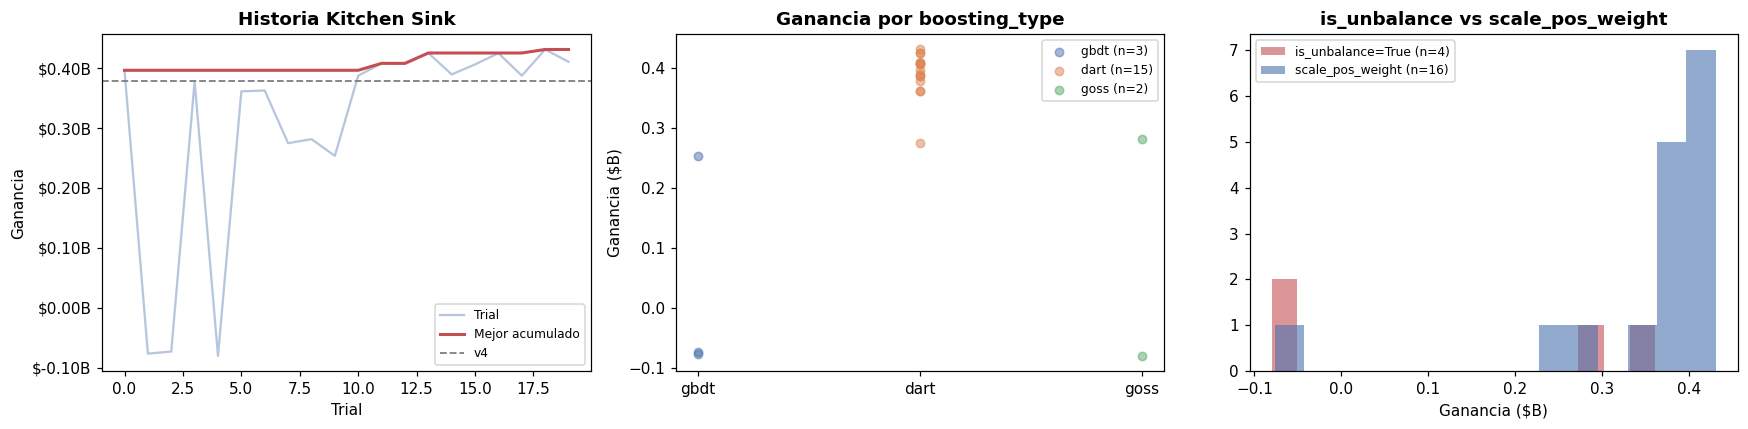

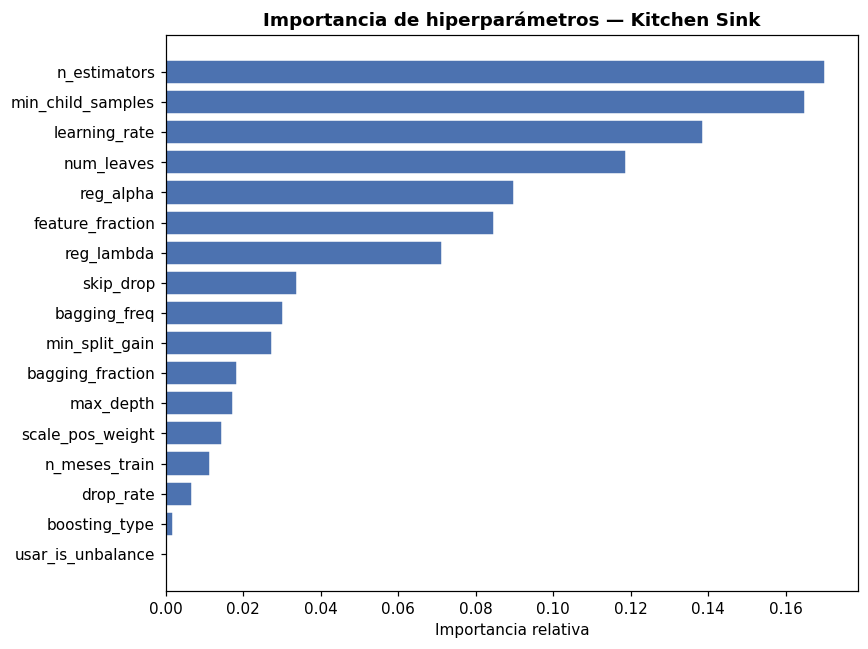

Top 5 hiperparámetros más influyentes:
  n_estimators: 0.1701
  min_child_samples: 0.1649
  learning_rate: 0.1387
  num_leaves: 0.1188
  reg_alpha: 0.0899


In [13]:
# Gráficos Kitchen Sink (solo si corrió en esta sesión)
if 'study_d' in dir():
    valores   = [t.value for t in study_d.trials if t.value is not None]
    mejor_acc = pd.Series(valores).cummax()

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    # Historia
    ax = axes[0]
    ax.plot(valores, alpha=0.4, color='#4C72B0', label='Trial')
    ax.plot(mejor_acc, color='#C44E52', lw=2, label='Mejor acumulado')
    ax.axhline(resultados_v4['fold_4']['ganancia'], color='gray', ls='--', lw=1.2, label='v4')
    ax.set_title('Historia Kitchen Sink', fontweight='bold')
    ax.set_xlabel('Trial')
    ax.set_ylabel('Ganancia')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e9:.2f}B'))
    ax.legend(fontsize=8)

    # boosting_type vs ganancia
    ax = axes[1]
    for bt, color in [('gbdt', '#4C72B0'), ('dart', '#DD8452'), ('goss', '#55A868')]:
        bt_trials = [(t.params.get('boosting_type'), t.value)
                     for t in study_d.trials
                     if t.value is not None and t.params.get('boosting_type') == bt]
        if bt_trials:
            g_vals = [v for _, v in bt_trials]
            ax.scatter([bt] * len(g_vals), [v/1e9 for v in g_vals],
                       alpha=0.5, color=color, s=30, label=f'{bt} (n={len(g_vals)})')
    ax.set_title('Ganancia por boosting_type', fontweight='bold')
    ax.set_ylabel('Ganancia ($B)')
    ax.legend(fontsize=8)

    # is_unbalance vs scale_pos_weight
    ax = axes[2]
    is_unb = [(t.params.get('usar_is_unbalance'), t.value)
               for t in study_d.trials if t.value is not None]
    for val, color, label in [(True, '#C44E52', 'is_unbalance=True'),
                               (False, '#4C72B0', 'scale_pos_weight')]:
        g_vals = [v/1e9 for u, v in is_unb if u == val]
        if g_vals:
            ax.hist(g_vals, bins=15, alpha=0.6, color=color, label=f'{label} (n={len(g_vals)})')
    ax.set_title('is_unbalance vs scale_pos_weight', fontweight='bold')
    ax.set_xlabel('Ganancia ($B)')
    ax.legend(fontsize=8)

    plt.tight_layout()
    plt.show()

    # Importancia de hiperparámetros
    try:
        importances = optuna.importance.get_param_importances(study_d)
        pi = list(importances.keys())
        vi = list(importances.values())
        si = np.argsort(vi)
        fig, ax = plt.subplots(figsize=(8, 6))
        ax.barh([pi[i] for i in si], [vi[i] for i in si], color='#4C72B0', edgecolor='white')
        ax.set_title('Importancia de hiperparámetros — Kitchen Sink', fontweight='bold')
        ax.set_xlabel('Importancia relativa')
        plt.tight_layout()
        plt.show()
        print('Top 5 hiperparámetros más influyentes:')
        for p, v in sorted(importances.items(), key=lambda x: -x[1])[:5]:
            print(f'  {p}: {v:.4f}')
    except Exception:
        print('(Importancia requiere más trials)')
else:
    print('(Gráficos disponibles solo si Kitchen Sink corrió en esta sesión)')

---
## 8 · Walk-forward con el ganador final

In [16]:
# Cargamos p_v5 si no está en memoria (por si Optuna corrió en esta sesión)
if 'p_v5' not in dir():
    with open(CKPT_V5) as f:
        p_v5 = json.load(f)
    print(f'p_v5 cargado desde disco')
    print(f'Ganancia: ${p_v5["ganancia_optuna_fold4"]:,.0f}')

# También reconstruimos las variables que dependen de p_v5
if 'PARAMS_OPT_D' not in dir():
    bp = {k: v for k, v in p_v5.items()
          if k not in {'ganancia_optuna_fold4','n_trials_completados','fecha','experimento','estado'}}

    N_MESES_TRAIN_D   = p_v5.get('n_meses_train', 3)
    USAR_IS_UNBALANCE = p_v5.get('usar_is_unbalance', False)

    PARAMS_OPT_D = {
        'objective': 'binary', 'metric': 'binary_logloss',
        'boosting_type': bp.get('boosting_type', 'gbdt'),
        'verbosity': -1, 'n_jobs': -1, 'random_state': SEED,
        'num_leaves':        bp['num_leaves'],
        'max_depth':         bp['max_depth'],
        'learning_rate':     bp['learning_rate'],
        'n_estimators':      bp['n_estimators'],
        'min_child_samples': bp['min_child_samples'],
        'feature_fraction':  bp['feature_fraction'],
        'bagging_fraction':  bp.get('bagging_fraction', 1.0),
        'bagging_freq':      bp.get('bagging_freq', 0),
        'reg_alpha':         bp['reg_alpha'],
        'reg_lambda':        bp['reg_lambda'],
        'min_split_gain':    bp['min_split_gain'],
    }
    if USAR_IS_UNBALANCE:
        PARAMS_OPT_D['is_unbalance'] = True
    else:
        PARAMS_OPT_D['scale_pos_weight'] = bp.get('scale_pos_weight', SCALE_NATURAL * 2)
    if bp.get('boosting_type') == 'dart':
        PARAMS_OPT_D['drop_rate'] = bp.get('drop_rate', 0.1)
        PARAMS_OPT_D['skip_drop'] = bp.get('skip_drop', 0.5)

    print(f'PARAMS_OPT_D reconstruido')
    print(f'boosting_type: {PARAMS_OPT_D["boosting_type"]}')
    print(f'n_meses_train: {N_MESES_TRAIN_D}')
    print(f'is_unbalance: {USAR_IS_UNBALANCE}')

p_v5 cargado desde disco
Ganancia: $430,980,000


In [17]:
# Ganador entre A, B, C y D
g_D_f4 = p_v5.get('ganancia_optuna_fold4') if CKPT_V5.exists() else study_d.best_value

candidatos = {
    'A': resultados_A.get('fold_4', {}).get('ganancia', 0),
    'B': resultados_B.get('fold_4', {}).get('ganancia', 0),
    'C': resultados_C.get('fold_4', {}).get('ganancia', 0),
    'D': g_D_f4,
}
GANADOR = max(candidatos, key=candidatos.get)

print('Ganancias fold_4 por experimento:')
for exp, g in candidatos.items():
    marca = ' ← GANADOR' if exp == GANADOR else ''
    print(f'  Exp {exp}: ${g:,.0f}{marca}')

# Seleccionamos los params del ganador
if GANADOR == 'A':
    PARAMS_FINAL = params_A
    MESES_TRAIN_FINAL = [202103, 202104, 202105]
elif GANADOR == 'B':
    PARAMS_FINAL = params_B
    MESES_TRAIN_FINAL = [202103, 202104, 202105]
elif GANADOR == 'C':
    PARAMS_FINAL = params_C
    MESES_TRAIN_FINAL = [202104, 202105]  # ventana 2 meses
else:  # D
    PARAMS_FINAL = PARAMS_OPT_D
    meses_disp = [202103, 202104, 202105]
    MESES_TRAIN_FINAL = meses_disp[-N_MESES_TRAIN_D:]

print(f'\nUsando params del Exp {GANADOR}')
print(f'Meses de train para el walk-forward: {MESES_TRAIN_FINAL}')

Ganancias fold_4 por experimento:
  Exp A: $354,420,000
  Exp B: $390,610,000
  Exp C: $319,715,000
  Exp D: $430,980,000 ← GANADOR

Usando params del Exp D
Meses de train para el walk-forward: [202103, 202104, 202105]


In [18]:
# Walk-forward completo con el ganador
# Para C y D, usamos la ventana adecuada por fold
def get_meses_train_fold(fold_nombre, n_meses_ventana=3):
    todos = [202103, 202104, 202105]
    fold_map = {
        'fold_2': [202103],
        'fold_3': [202103, 202104],
        'fold_4': [202103, 202104, 202105],
    }
    meses_disponibles = fold_map[fold_nombre]
    return meses_disponibles[-n_meses_ventana:]

n_ventana = N_MESES_TRAIN_D if GANADOR == 'D' else (2 if GANADOR == 'C' else 3)

resultados_wf = []

for fold in FOLDS:
    meses_tr = get_meses_train_fold(fold['nombre'], n_ventana)
    print(f"\n{'='*55}")
    print(f"  {fold['nombre'].upper()} | Exp {GANADOR} | train: {meses_tr}")
    print('='*55)

    Xtr, ytr, Xte, yte = get_split(meses_tr, fold['test'])
    params_wf = {**PARAMS_FINAL, 'random_state': SEED}

    modelo = lgb.LGBMClassifier(**params_wf)
    if PARAMS_FINAL.get('boosting_type') == 'dart':
        modelo.fit(Xtr, ytr, callbacks=[lgb.log_evaluation(-1)])
    else:
        modelo.fit(Xtr, ytr,
                   eval_set=[(Xte, yte)],
                   callbacks=[lgb.early_stopping(50, verbose=False),
                              lgb.log_evaluation(-1)])

    prob = modelo.predict_proba(Xte)[:, 1]
    auc  = roc_auc_score(yte, prob)
    opt  = threshold_optimo(yte.values, prob)

    print(f'  AUC: {auc:.4f} | Ganancia: ${opt["ganancia"]:,.0f} | '
          f'N: {opt["n_intervenidos"]:,} | thresh: {opt["threshold"]:.4f}')

    resultados_wf.append({
        'fold': fold['nombre'], 'mes_test': fold['test'],
        'experimento': f'v5_exp{GANADOR}',
        'meses_train': str(meses_tr),
        'n_train': len(ytr), 'n_test': len(yte),
        'n_baja2_test': int(yte.sum()),
        'auc': round(auc, 4), 'ganancia': opt['ganancia'],
        'threshold_opt': opt['threshold'],
        'tp': opt['tp'], 'fp': opt['fp'],
        'n_intervenidos': opt['n_intervenidos'],
    })
    del Xtr, ytr, Xte, yte, modelo, prob; gc.collect()

df_wf = pd.DataFrame(resultados_wf)
print(f"\n{'='*55}\nRESUMEN WALK-FORWARD v5 (Exp {GANADOR})\n{'='*55}")
print(df_wf[['fold','auc','ganancia','threshold_opt','n_intervenidos']].to_string(index=False))

# Comparativa final completa
print(f'\n--- vs versiones anteriores (fold_4) ---')
refs = {'v3': 377_685_000, 'v4': candidatos.get('A', 0),
        f'Exp {GANADOR}': df_wf[df_wf.fold=='fold_4']['ganancia'].values[0]}
for nombre, g in refs.items():
    print(f'  {nombre}: ${g:,.0f}')


  FOLD_2 | Exp D | train: [202103]
  AUC: 0.9110 | Ganancia: $527,202,500 | N: 8,669.0 | thresh: 0.7970

  FOLD_3 | Exp D | train: [202103, 202104]
  AUC: 0.8908 | Ganancia: $280,445,000 | N: 7,402.0 | thresh: 0.8510

  FOLD_4 | Exp D | train: [202103, 202104, 202105]
  AUC: 0.9018 | Ganancia: $430,980,000 | N: 13,488.0 | thresh: 0.6890

RESUMEN WALK-FORWARD v5 (Exp D)
  fold    auc    ganancia  threshold_opt  n_intervenidos
fold_2 0.9110 527202500.0          0.797          8669.0
fold_3 0.8908 280445000.0          0.851          7402.0
fold_4 0.9018 430980000.0          0.689         13488.0

--- vs versiones anteriores (fold_4) ---
  v3: $377,685,000
  v4: $354,420,000
  Exp D: $430,980,000


In [19]:
# Guardamos métricas
df_wf['timestamp'] = datetime.now().isoformat()
if ARCHIVO_METRICAS.exists():
    hist = pd.read_csv(ARCHIVO_METRICAS)
    df_wf_save = pd.concat([hist, df_wf], ignore_index=True)
else:
    df_wf_save = df_wf
df_wf_save.to_csv(ARCHIVO_METRICAS, index=False)
print(f'✓ Métricas guardadas')

✓ Métricas guardadas


---
## 9 · Semillerio y submission

In [20]:
# Centro del semillerio: N óptimo del fold_4
N_OPT = int(df_wf[df_wf.fold == 'fold_4']['n_intervenidos'].values[0])
paso  = max(100, int(N_OPT * 0.025))
CORTES_N = [max(8000, min(15000, N_OPT + i * paso)) for i in range(-2, 3)]
SEMILLAS  = [42, 123, 777, 2024]
TS        = datetime.now().strftime('%m%d_%H%M')

# Meses de train para el modelo final (todos los disponibles con target)
meses_disp_todos = [202103, 202104, 202105, 202106]
if GANADOR in ('C',) or (GANADOR == 'D' and N_MESES_TRAIN_D < 4):
    MESES_TRAIN_FINAL_SUB = meses_disp_todos[-max(2, N_MESES_TRAIN_D):]
else:
    MESES_TRAIN_FINAL_SUB = meses_disp_todos  # todos

mask_tf = df[COL_PERIODO].isin(MESES_TRAIN_FINAL_SUB) & df[TARGET].notna()
X_tf    = df.loc[mask_tf, FEATURE_COLS]
y_tf    = df.loc[mask_tf, TARGET].astype(int)
mask_p  = df[COL_PERIODO] == MES_PREDECIR
X_pred  = df.loc[mask_p, FEATURE_COLS]
ids_pred = df.loc[mask_p, COL_ID].values

print(f'Train final: {len(y_tf):,} (baja2={y_tf.sum():,}) | meses: {MESES_TRAIN_FINAL_SUB}')
print(f'A predecir: {len(X_pred):,} clientes')
print(f'Centro semillerio: {N_OPT:,} | Cortes: {CORTES_N}')

probs_semillerio = []
for semilla in SEMILLAS:
    print(f'Entrenando semilla {semilla}...', end=' ')
    params_s = {**PARAMS_FINAL, 'random_state': semilla}
    modelo = lgb.LGBMClassifier(**params_s)
    modelo.fit(X_tf, y_tf, callbacks=[lgb.log_evaluation(-1)])
    probs_semillerio.append(modelo.predict_proba(X_pred)[:, 1])
    print('✓')
    del modelo; gc.collect()

del X_tf, y_tf; gc.collect()
print('\n✓ Semillerio completo')

Train final: 488,185 (baja2=3,107) | meses: [202104, 202105, 202106]
A predecir: 164,647 clientes
Centro semillerio: 13,488 | Cortes: [12814, 13151, 13488, 13825, 14162]
Entrenando semilla 42... ✓
Entrenando semilla 123... ✓
Entrenando semilla 777... ✓
Entrenando semilla 2024... ✓

✓ Semillerio completo


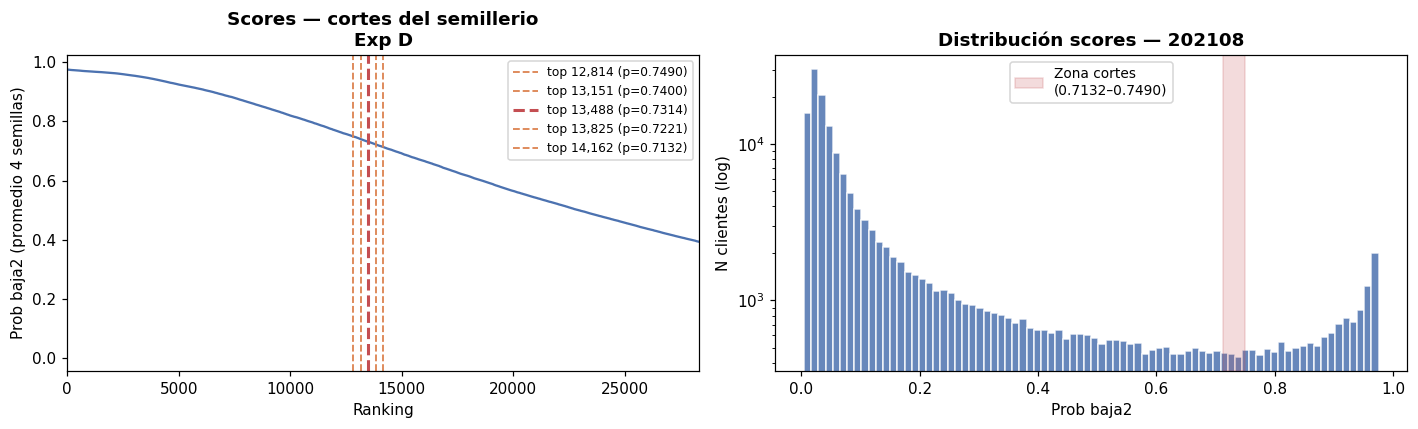

In [21]:
# Gráfico de scores con cortes
prob_prom = np.mean(probs_semillerio, axis=0)
scores_sorted = np.sort(prob_prom)[::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
ax.plot(np.arange(1, len(scores_sorted)+1), scores_sorted, color='#4C72B0', lw=1.5)
for n in CORTES_N:
    t = float(scores_sorted[min(n-1, len(scores_sorted)-1)])
    color = '#C44E52' if n == N_OPT else '#DD8452'
    lw = 2.0 if n == N_OPT else 1.2
    ax.axvline(n, color=color, ls='--', lw=lw, label=f'top {n:,} (p={t:.4f})')
ax.set_xlim(0, max(CORTES_N) * 2)
ax.set_title(f'Scores — cortes del semillerio\nExp {GANADOR}', fontweight='bold')
ax.set_xlabel('Ranking')
ax.set_ylabel('Prob baja2 (promedio 4 semillas)')
ax.legend(fontsize=8)

ax = axes[1]
ax.hist(prob_prom, bins=80, color='#4C72B0', edgecolor='white', alpha=0.85)
ax.set_yscale('log')
umbral_min = float(scores_sorted[max(CORTES_N)-1])
umbral_max = float(scores_sorted[min(CORTES_N)-1])
ax.axvspan(umbral_min, umbral_max, alpha=0.2, color='#C44E52',
           label=f'Zona cortes\n({umbral_min:.4f}–{umbral_max:.4f})')
ax.set_title('Distribución scores — 202108', fontweight='bold')
ax.set_xlabel('Prob baja2')
ax.set_ylabel('N clientes (log)')
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

In [22]:
# Generación de archivos
archivos = []
print(f'Generando archivos en: {RUTA_SUBS}')

for i_s, semilla in enumerate(SEMILLAS):
    prob_s = probs_semillerio[i_s]
    for n_corte in CORTES_N:
        ranking = np.argsort(prob_s)[::-1][:n_corte]
        ids_int = ids_pred[ranking].astype(int)
        nombre  = f'v5{GANADOR}_sem{semilla}_top{n_corte}_{TS}'
        ruta    = RUTA_SUBS / f'{nombre}.csv'
        pd.Series(ids_int).to_csv(ruta, index=False, header=False)
        archivos.append({'nombre': nombre, 'semilla': semilla,
                         'n_corte': n_corte, 'n_clientes': len(ids_int)})
        print(f'  ✓ {nombre}.csv')

pd.DataFrame(archivos).to_csv(RUTA_SUBS / f'log_{TS}.csv', index=False)

# Verificación
ruta_v = RUTA_SUBS / f'{archivos[0]["nombre"]}.csv'
df_v = pd.read_csv(ruta_v, header=None)
tiene_e = df_v[0].astype(str).str.lower().str.contains('e').any()
print(f'\nVerificación: sin notación científica: {"✓" if not tiene_e else "✗"}')
print(f'Total archivos: {len(archivos)}')

Generando archivos en: /content/drive/MyDrive/Maestría Data Mining/DM en EyF/Competencia 1/submissions2
  ✓ v5D_sem42_top12814_1007_1833.csv
  ✓ v5D_sem42_top13151_1007_1833.csv
  ✓ v5D_sem42_top13488_1007_1833.csv
  ✓ v5D_sem42_top13825_1007_1833.csv
  ✓ v5D_sem42_top14162_1007_1833.csv
  ✓ v5D_sem123_top12814_1007_1833.csv
  ✓ v5D_sem123_top13151_1007_1833.csv
  ✓ v5D_sem123_top13488_1007_1833.csv
  ✓ v5D_sem123_top13825_1007_1833.csv
  ✓ v5D_sem123_top14162_1007_1833.csv
  ✓ v5D_sem777_top12814_1007_1833.csv
  ✓ v5D_sem777_top13151_1007_1833.csv
  ✓ v5D_sem777_top13488_1007_1833.csv
  ✓ v5D_sem777_top13825_1007_1833.csv
  ✓ v5D_sem777_top14162_1007_1833.csv
  ✓ v5D_sem2024_top12814_1007_1833.csv
  ✓ v5D_sem2024_top13151_1007_1833.csv
  ✓ v5D_sem2024_top13488_1007_1833.csv
  ✓ v5D_sem2024_top13825_1007_1833.csv
  ✓ v5D_sem2024_top14162_1007_1833.csv

Verificación: sin notación científica: ✓
Total archivos: 20


In [23]:
nombre_submit = f'v5{GANADOR}_semillerio_{TS}'
print('=' * 60)
print('SUBMIT EN ZULIP')
print('=' * 60)
print(f'Cuerpo: submit {nombre_submit}')
print(f'Adjuntos: {len(archivos)} archivos .csv de {RUTA_SUBS.name}/')
print(f'(sin el log_{TS}.csv)')
print()
print(f'Experimento ganador: {GANADOR}')
print(f'Centro: {N_OPT:,} clientes | Cortes: {CORTES_N}')
print(f'Ganancia fold_4: ${candidatos[GANADOR]:,.0f}')
print(f'Submit anterior: 85.85M público')

del df; gc.collect()
print('\n✓ Notebook v5 completada.')

SUBMIT EN ZULIP
Cuerpo: submit v5D_semillerio_1007_1833
Adjuntos: 20 archivos .csv de submissions2/
(sin el log_1007_1833.csv)

Experimento ganador: D
Centro: 13,488 clientes | Cortes: [12814, 13151, 13488, 13825, 14162]
Ganancia fold_4: $430,980,000
Submit anterior: 85.85M público

✓ Notebook v5 completada.
